# Chapter 6 — coupled phase and coupling-efficiency time series

Loads only paired `*_argA.npy` and `*_etas.npy` (also `*_eta.npy`) files. Large phase-screen arrays with other endings are never loaded.

Set the data directory and **sampling interval of these simulation arrays**, not the QKD reference frequency. Until a sampling interval is supplied, plots use sample index and durations are unknown. Assumes numeric one-dimensional arrays: phase in radians, efficiency as a fraction, with matched sampling and start time.

The default Chapter 6 selection is Night (slow), Medium, Day, Night Fast and Night Very Fast; verify this against your actual emulation inputs. Medium/Day fast variants are discovered but excluded from the Chapter 6 table by default.


In [1]:
from pathlib import Path
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(".")  # Folder containing the .npy files
OUTPUT_DIR = Path("chapter6_phase_coupling_output")
SAVE_OUTPUTS = True

DT_S = 200/200000  # REQUIRED for seconds: e.g. actual simulation sample interval
DT_BY_CASE = {}  # Optional overrides, e.g. {"night_fast": actual_interval}
PHASE_UNITS = "rad"  # "rad" or "deg"
ETA_UNITS = "fraction"  # "fraction" or "percent"
DDOF = 0  # Descriptive variance of each finite record, not uncertainty
PHASE_REPRESENTATION = "unwrapped"  # "unwrapped" or "wrapped"
WINDOW_S = None  # Optional statistics/plot window, e.g. (0.0, 10.0)
PLOT_WINDOW_S = None  # Optional display-only window
MAX_PLOT_POINTS = 20000  # Plot decimation only; statistics use every sample

CHAPTER6_CASES = ["night", "medium", "day", "night_fast", "night_veryfast"]
PLOT_CASES = ["night", "day"]  # Any discovered cases; one 8 x 6 figure per case
LABELS = {
    "night": "Night (slow)", "medium": "Medium", "day": "Day",
    "night_fast": "Night Fast", "night_veryfast": "Night Very Fast",
}


## Discovery and validation

Files are matched by their complete common stem. Missing partners are reported. No pickled objects are loaded. Non-finite values, unequal lengths and efficiencies outside [0, 1] stop analysis rather than being silently discarded. No phase samples are masked on coupling, so variances describe the whole record; phase close to zero coupling requires particular caution.


In [3]:
PATTERN = re.compile(
    r"^rx_300m_(day|medium|night)_2_long(?:_(fast|veryfast))?_(argA|etas|eta)\.npy$",
    re.IGNORECASE
)

def discover(folder):
    pairs = {}
    for path in sorted(folder.glob("*.npy")):
        match = PATTERN.fullmatch(path.name)
        if match is None:
            continue
        condition, speed, kind = match.groups()
        key = condition.lower() + ("_" + speed.lower() if speed else "")
        kind = "phase" if kind.lower() == "arga" else "eta"
        if kind in pairs.setdefault(key, {}):
            raise ValueError(f"Duplicate {kind} file for {key}")
        pairs[key][kind] = path
    complete = {}
    for key, pair in pairs.items():
        if set(pair) == {"phase", "eta"}:
            complete[key] = pair
        else:
            warnings.warn(f"Skipping incomplete pair: {key}: {list(pair)}")
    if not complete:
        raise FileNotFoundError(f"No complete phase/eta pairs in {folder.resolve()}")
    return complete

def load_vector(path):
    array = np.load(path, allow_pickle=False)
    if np.iscomplexobj(array) or not np.issubdtype(array.dtype, np.number):
        raise ValueError(f"{path.name}: expected real numeric values")
    array = np.asarray(array, dtype=float).squeeze()
    if array.ndim != 1 or array.size < 2:
        raise ValueError(f"{path.name}: expected a 1D series, got {array.shape}")
    if not np.all(np.isfinite(array)):
        raise ValueError(f"{path.name}: non-finite values; inspect before analysis")
    return array

def load_pair(key, pair):
    phase, eta = load_vector(pair["phase"]), load_vector(pair["eta"])
    if phase.size != eta.size:
        raise ValueError(f"{key}: phase and eta have unequal lengths")
    if PHASE_UNITS == "deg":
        phase = np.deg2rad(phase)
    elif PHASE_UNITS != "rad":
        raise ValueError("PHASE_UNITS must be rad or deg")
    if ETA_UNITS == "percent":
        eta = eta / 100
    elif ETA_UNITS != "fraction":
        raise ValueError("ETA_UNITS must be fraction or percent")
    if np.any((eta < 0) | (eta > 1)):
        raise ValueError(f"{key}: efficiency must be between 0 and 1")
    dt = DT_BY_CASE.get(key, DT_S)
    if dt is not None and (not np.isfinite(dt) or dt <= 0):
        raise ValueError("Sampling interval must be positive and finite")
    t = np.arange(phase.size) * (dt if dt is not None else 1.0)
    unwrapped = np.unwrap(phase)
    wrapped = np.angle(np.exp(1j * phase))
    keep = np.ones(phase.size, dtype=bool)
    if WINDOW_S is not None:
        if dt is None:
            raise ValueError("Set DT_S before selecting WINDOW_S")
        keep = (t >= WINDOW_S[0]) & (t <= WINDOW_S[1])
    if keep.sum() < 2:
        raise ValueError(f"{key}: fewer than two samples in selected window")
    return dict(
        t=t[keep], wrapped=wrapped[keep], unwrapped=unwrapped[keep],
        eta=eta[keep], amplitude=np.sqrt(eta[keep]), dt=dt,
        phase_file=pair["phase"].name, eta_file=pair["eta"].name
    )

pairs = discover(DATA_DIR)
display(pd.DataFrame([
    {"case": key, **{kind: path.name for kind, path in pair.items()}}
    for key, pair in pairs.items()
]))
records = {key: load_pair(key, pair) for key, pair in pairs.items()}


,case,phase,eta
0,day,rx_300m_day_2_long_argA.npy,rx_300m_day_2_long_etas.npy
1,day_fast,rx_300m_day_2_long_fast_argA.npy,rx_300m_day_2_long_fast_etas.npy
2,day_veryfast,rx_300m_day_2_long_veryfast_argA.npy,rx_300m_day_2_long_veryfast_etas.npy
3,medium,rx_300m_medium_2_long_argA.npy,rx_300m_medium_2_long_etas.npy
4,medium_fast,rx_300m_medium_2_long_fast_argA.npy,rx_300m_medium_2_long_fast_etas.npy
5,medium_veryfast,rx_300m_medium_2_long_veryfast_argA.npy,rx_300m_medium_2_long_veryfast_etas.npy
6,night,rx_300m_night_2_long_argA.npy,rx_300m_night_2_long_etas.npy
7,night_fast,rx_300m_night_2_long_fast_argA.npy,rx_300m_night_2_long_fast_etas.npy
8,night_veryfast,rx_300m_night_2_long_veryfast_argA.npy,rx_300m_night_2_long_veryfast_etas.npy


## Variances for quotation

Coupling efficiency is $\eta=|\mathcal C|^2$; the normalized **field-amplitude magnitude** is $|\mathcal C|=\sqrt{\eta}$. Their variances are different, so both are reported. These are not variances of amplitude in volts, optical power in watts, or of the complex field.

Phase variance uses the chosen representation, with its mean removed by the variance operation, **without detrending**. Unwrapping assumes sufficiently resolved inter-sample phase evolution; it can be unreliable during deep fades or undersampling. Wrapped linear variance depends on the branch cut and should not be quoted blindly. Both are supplied for inspection, along with circular variance $1-|\langle e^{i\phi}\rangle|$ (dimensionless, not rad²). These are single-channel coupled phases, not automatically the differential phase between two independent QKD arms, and should not be converted directly to QBER without a differential-phase and tracking model.

No estimate here is a confidence interval: temporal correlation and record duration affect statistical inference. Check that statistics windows match the records used for emulation.


In [5]:
def summarise(key, record):
    if PHASE_REPRESENTATION not in ("wrapped", "unwrapped"):
        raise ValueError("Choose wrapped or unwrapped phase")
    p = record[PHASE_REPRESENTATION]
    eta, amplitude = record["eta"], record["amplitude"]
    n = len(p)
    if DDOF not in (0, 1) or n <= DDOF:
        raise ValueError("DDOF must be 0 or 1, with enough samples")
    var = lambda values: float(np.var(values, ddof=DDOF))
    result = {
        "case": key, "label": LABELS.get(key, key),
        "n": n, "dt_s": record["dt"],
        "span_s": (n - 1) * record["dt"] if record["dt"] is not None else np.nan,
        "phase_representation": PHASE_REPRESENTATION, "ddof": DDOF,
        "phase_variance_rad2": var(p),
        "phase_std_rad": float(np.std(p, ddof=DDOF)),
        "phase_wrapped_variance_rad2": var(record["wrapped"]),
        "phase_unwrapped_variance_rad2": var(record["unwrapped"]),
        "phase_circular_variance": float(np.clip(
            1 - abs(np.mean(np.exp(1j * record["wrapped"]))), 0, 1)),
        "eta_mean": float(np.mean(eta)),
        "eta_variance": var(eta),
        "eta_std": float(np.std(eta, ddof=DDOF)),
        "amplitude_mean": float(np.mean(amplitude)),
        "amplitude_variance": var(amplitude),
        "eta_min": float(np.min(eta)),
        "phase_file": record["phase_file"], "eta_file": record["eta_file"]
    }
    return result

all_summary = pd.DataFrame([summarise(k, r) for k, r in records.items()])
missing = [k for k in CHAPTER6_CASES if k not in records]
if missing:
    warnings.warn(f"Missing Chapter 6 cases: {missing}; no values invented.")
summary = (all_summary.set_index("case")
           .reindex([k for k in CHAPTER6_CASES if k in records])
           .reset_index())
display(summary[[
    "case", "n", "span_s", "phase_variance_rad2",
    "eta_mean", "eta_variance", "amplitude_variance",
    "phase_circular_variance"
]])


,case,n,span_s,phase_variance_rad2,eta_mean,eta_variance,amplitude_variance,phase_circular_variance
0,night,200000,199.999,16.110308,0.900738,0.000454,0.000130,0.979946
1,medium,200000,199.999,118.824589,0.764079,0.013212,0.005227,0.977569
2,day,200000,199.999,889.845843,0.508644,0.042109,0.030132,0.996650
3,night_fast,200000,199.999,14.626993,0.898691,0.000383,0.000109,0.970795
4,night_veryfast,200000,199.999,13.377552,0.894624,0.000416,0.000119,0.977793


## Selected time traces — thesis format

One 8 × 6 inch figure per selected case; upper panel: coupled phase, lower panel: coupling efficiency. Both panels share time. Plot thinning never changes the numerical statistics but can conceal brief features; set MAX_PLOT_POINTS=None for full-resolution display. Use the same time range for comparisons. Raw phase offsets are retained.


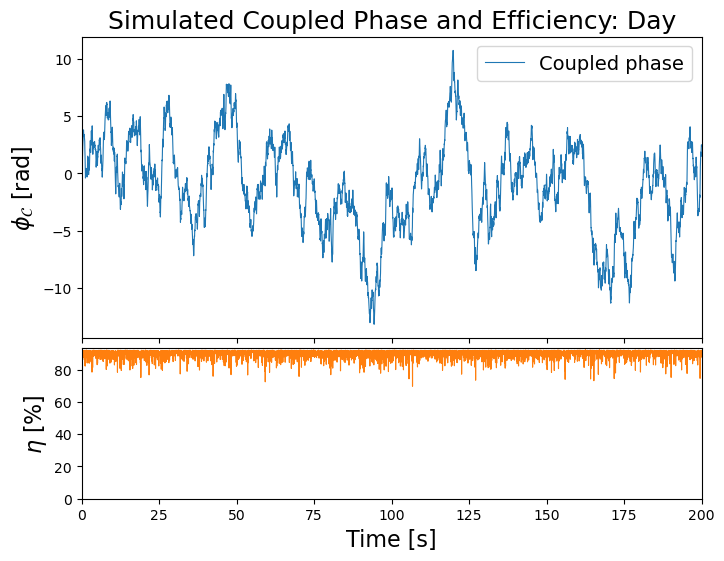

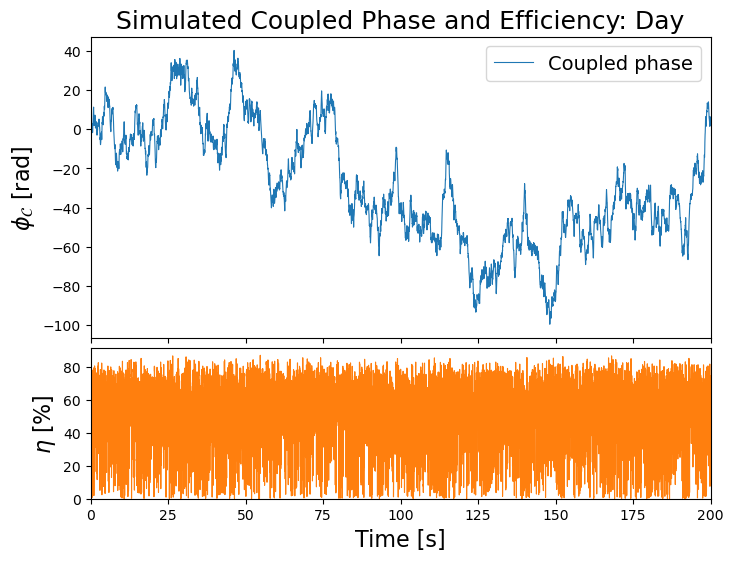

In [11]:
def plot_case(key, record):
    plt.rcParams.update({"font.size": 10})
    plt.rc("axes", titlesize=18)
    plt.rc("axes", labelsize=16)
    fig, axs = plt.subplots(2, 1, sharex=True,
                            gridspec_kw={"height_ratios": [2, 1]})
    fig.set_size_inches(8, 6)
    t = record["t"]
    indices = np.arange(len(t))
    if PLOT_WINDOW_S is not None:
        if record["dt"] is None:
            raise ValueError("Set DT_S before selecting PLOT_WINDOW_S")
        indices = indices[(t >= PLOT_WINDOW_S[0]) & (t <= PLOT_WINDOW_S[1])]
    if indices.size == 0:
        raise ValueError(f"{key}: empty plotting window")
    if MAX_PLOT_POINTS is not None:
        if MAX_PLOT_POINTS < 2:
            raise ValueError("MAX_PLOT_POINTS must be at least 2")
        stride = max(1, int(np.ceil(indices.size / MAX_PLOT_POINTS)))
        indices = indices[::stride]
    axs[0].plot(t[indices], record[PHASE_REPRESENTATION][indices],
                color="tab:blue", linewidth=0.8, label="Coupled phase")
    axs[1].plot(t[indices], 100 * record["eta"][indices],
                color="tab:orange", linewidth=0.8, label="Coupling efficiency")
    axs[0].set_ylabel(r"$\phi_{\mathcal{C}}$ [rad]")
    axs[1].set_ylabel(r"$\eta$ [%]")
    axs[1].set_xlabel("Time [s]" if record["dt"] is not None else "Sample index")
    axs[0].set_title('Simulated Coupled Phase and Efficiency: Day')
    axs[0].tick_params(labelbottom=False)
    axs[1].set_ylim(bottom=0)
    axs[0].legend(loc="upper right", fontsize=14, frameon=True)
    axs[0].set_xlim(0,200)
    axs[1].set_xlim(0,200)
    fig.subplots_adjust(hspace=0.045)
    return fig, axs

figures = {}
for key in PLOT_CASES:
    if key not in records:
        warnings.warn(f"Cannot plot missing case: {key}")
        continue
    figures[key] = plot_case(key, records[key])
plt.show()


## Export and suggested wording

Set SAVE_OUTPUTS=True to export PDF/PNG figures, full and Chapter 6 CSV tables, and quotation-ready text. Efficiency/amplitude variances are dimensionless; to express efficiency variance in squared percentage points multiply by 10,000, not 100. The text identifies the phase representation and record span; verify sampling and case mapping before copying into the thesis.


In [13]:
sentences = []
for _, row in summary.iterrows():
    duration = (f"a {row['span_s']:.6g} s sampled span"
                if pd.notna(row["span_s"]) else
                f"{int(row['n'])} samples (sampling interval not specified)")
    sentences.append(
        f"For the {row['label']} case, over {duration}, the "
        f"{row['phase_representation']} coupled-phase variance was "
        f"{row['phase_variance_rad2']:.6g} rad². The mean coupling efficiency "
        f"was {100 * row['eta_mean']:.6g}%, with variance "
        f"{row['eta_variance']:.6g}; the variance of the normalized "
        f"field-amplitude magnitude, sqrt(eta), was "
        f"{row['amplitude_variance']:.6g}. Variances use ddof={DDOF}, "
        "with no detrending."
    )
print("\n\n".join(sentences))

if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    all_summary.to_csv(OUTPUT_DIR / "all_phase_coupling_statistics.csv", index=False)
    summary.to_csv(OUTPUT_DIR / "chapter6_phase_coupling_statistics.csv", index=False)
    (OUTPUT_DIR / "chapter6_variance_wording.txt").write_text(
        "\n\n".join(sentences), encoding="utf-8")
    for key, (fig, axs) in figures.items():
        fig.savefig(OUTPUT_DIR / f"{key}_phase_coupling.pdf", dpi=300)
        fig.savefig(OUTPUT_DIR / f"{key}_phase_coupling.png", dpi=300)
    print(f"Saved to {OUTPUT_DIR.resolve()}")


For the Night (slow) case, over a 199.999 s sampled span, the unwrapped coupled-phase variance was 16.1103 rad². The mean coupling efficiency was 90.0738%, with variance 0.000453936; the variance of the normalized field-amplitude magnitude, sqrt(eta), was 0.000130057. Variances use ddof=0, with no detrending.

For the Medium case, over a 199.999 s sampled span, the unwrapped coupled-phase variance was 118.825 rad². The mean coupling efficiency was 76.4079%, with variance 0.0132121; the variance of the normalized field-amplitude magnitude, sqrt(eta), was 0.0052273. Variances use ddof=0, with no detrending.

For the Day case, over a 199.999 s sampled span, the unwrapped coupled-phase variance was 889.846 rad². The mean coupling efficiency was 50.8644%, with variance 0.0421089; the variance of the normalized field-amplitude magnitude, sqrt(eta), was 0.0301322. Variances use ddof=0, with no detrending.

For the Night Fast case, over a 199.999 s sampled span, the unwrapped coupled-phase var

## Phase-noise PSD — Welch analysis

Uses the same Hann-window Welch estimator as your PSDanalysis method, with explicit 50% overlap, per-segment mean removal and one-sided density scaling. The argA inputs already contain phase in radians: do NOT apply the intensity normalisation or arccos extraction to them. Use unwrapped phase to avoid artificial branch-cut jumps; check sampling and deep fades before trusting unwrapping.

Set DT_S (or DT_BY_CASE) above and rerun the loading cells first. Here fs=1/dt. In your original fs=N/t convention, t must mean N*dt, not the first-to-last timestamp span (N-1)*dt. Never use the 10/1000 Hz reference frequency as the simulation sampling rate without justification.

The default nperseg=1,000,000 is capped to the available samples, matching SciPy's usual behaviour. With 200,000 samples this gives one Hann-windowed segment, not multiple-segment averaging. Reduce PSD_NPERSEG (e.g. 16384) for smoother averaged estimates at reduced frequency resolution. Compare cases with the same segment duration when sampling rates differ. Full-resolution arrays are used, irrespective of plot thinning.

These files describe coupled single-channel phase, so the axis is S_phi, not S_delta_phi. A differential-phase PSD requires the relative phase of two arms (including correlations), or an explicit assumption of an ideal stable reference. No detector-noise ratio is plotted because no detector reference has been supplied. Integrated Welch PSD is a segment-detrended, window-weighted estimate and need not equal the full-record variance for drifting/nonstationary phase.


,case,n,fs_Hz,nperseg,noverlap,segments,segment_duration_s,bin_spacing_Hz,nyquist_Hz,integrated_psd_rad2
0,night,200000,1000.0,16384,8192,23,16.384,0.061035,500.0,8.180512
1,medium,200000,1000.0,16384,8192,23,16.384,0.061035,500.0,59.921915
2,day,200000,1000.0,16384,8192,23,16.384,0.061035,500.0,163.881544
3,night_fast,200000,1000.0,16384,8192,23,16.384,0.061035,500.0,11.931367
4,night_veryfast,200000,1000.0,16384,8192,23,16.384,0.061035,500.0,12.263091


Saved: C:\Users\Ry\chapter6_phase_coupling_output\atmospheric_conditions_phase_psd.pdf
Saved: C:\Users\Ry\chapter6_phase_coupling_output\atmospheric_conditions_phase_psd.png
Saved: C:\Users\Ry\chapter6_phase_coupling_output\night_wind_speeds_phase_psd.pdf
Saved: C:\Users\Ry\chapter6_phase_coupling_output\night_wind_speeds_phase_psd.png


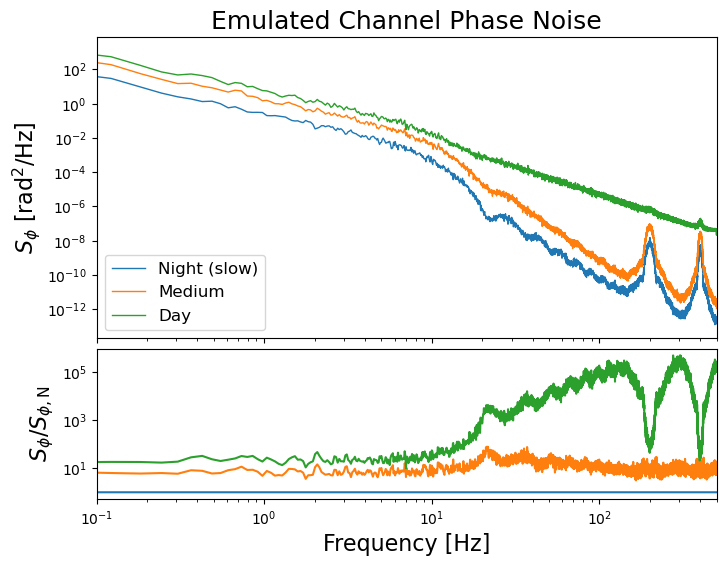

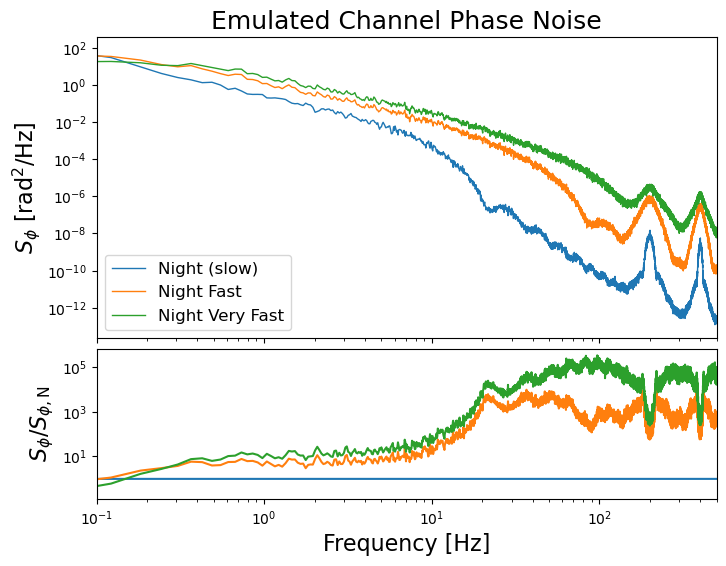

In [111]:
from scipy import signal
PSD_CASES = CHAPTER6_CASES.copy()
PSD_NPERSEG = 16384
PSD_XLIM = None  # e.g. (1, 1000); default uses measured positive frequencies
PSD_YLIM = None
PSD_SAVE = True

def PSDanalysis_phase(phi, dt_s, nperseg=int(1e6)):
    """Welch PSD for phase already in radians; no intensity inversion."""
    phi = np.asarray(phi, dtype=float)
    if phi.ndim != 1 or phi.size < 2 or not np.all(np.isfinite(phi)):
        raise ValueError("Expected a finite 1D phase array with >=2 samples")
    if dt_s is None or not np.isfinite(dt_s) or dt_s <= 0:
        raise ValueError("Set the simulation DT_S/DT_BY_CASE and reload records")
    if int(nperseg) != nperseg or nperseg < 2:
        raise ValueError("nperseg must be an integer >=2")
    nseg = min(int(nperseg), phi.size)
    noverlap = nseg // 2
    f, pxx = signal.welch(
        phi, fs=1.0 / dt_s, window="hann", nperseg=nseg,
        noverlap=noverlap, detrend="constant",
        return_onesided=True, scaling="density", average="mean"
    )
    metadata = {
        "n": phi.size, "fs_Hz": 1.0 / dt_s,
        "nperseg": nseg, "noverlap": noverlap,
        "segments": 1 + (phi.size - nseg) // (nseg - noverlap),
        "segment_duration_s": nseg * dt_s,
        "bin_spacing_Hz": (1.0 / dt_s) / nseg,
        "nyquist_Hz": 0.5 / dt_s,
        "integrated_psd_rad2": float(np.sum(pxx) * (f[1] - f[0])),
    }
    return f, pxx, metadata

psd_results = {}
psd_rows = []
for key in PSD_CASES:
    if key not in records:
        warnings.warn(f"Missing PSD case: {key}")
        continue
    record = records[key]
    if record["dt"] is None:
        warnings.warn(f"{key}: PSD skipped; set sampling interval and reload records")
        continue
    f, pxx, meta = PSDanalysis_phase(
        record["unwrapped"], record["dt"], PSD_NPERSEG)
    psd_results[key] = (f, pxx)
    psd_rows.append({"case": key, **meta})
    if meta["segments"] == 1:
        warnings.warn(f"{key}: one segment only; reduce PSD_NPERSEG for Welch averaging")

psd_summary = pd.DataFrame(psd_rows)
display(psd_summary)

PSD_REFERENCE = "night"
PSD_RATIO_YLIM = None
PSD_MARKERS_HZ = []  # Optional vertical markers, e.g. [61, 1000, 4000]

psd_figures = {}

PSD_GROUPS = {
    "atmospheric_conditions": ["night", "medium", "day"],
    "night_wind_speeds": ["night", "night_fast", "night_veryfast"],
}

plt.rcParams.update({'font.size': 10})
plt.rc('axes', titlesize=18)
plt.rc('axes', labelsize=16)


def relative_psd(f, pxx, ref_f, ref_pxx):
    """Divide by the reference at matching frequencies."""
    ratio = np.full_like(pxx, np.nan, dtype=float)

    if np.array_equal(f, ref_f):
        valid = (
            (f > 0)
            & np.isfinite(pxx)
            & np.isfinite(ref_pxx)
            & (pxx > 0)
            & (ref_pxx > 0)
        )
        ratio[valid] = pxx[valid] / ref_pxx[valid]
        return ratio

    # Different sampling rates/segment lengths can produce different grids.
    # Interpolate in log-log space, only within the reference's range.
    valid_ref = (
        (ref_f > 0)
        & np.isfinite(ref_pxx)
        & (ref_pxx > 0)
    )
    rf = ref_f[valid_ref]
    rp = ref_pxx[valid_ref]

    if rf.size < 2:
        raise ValueError("Insufficient positive reference PSD values.")

    valid = (
        (f >= rf[0])
        & (f <= rf[-1])
        & np.isfinite(pxx)
        & (pxx > 0)
    )
    reference = np.exp(
        np.interp(np.log(f[valid]), np.log(rf), np.log(rp))
    )
    ratio[valid] = pxx[valid] / reference

    return ratio


if PSD_REFERENCE not in psd_results:
    raise ValueError(
        f"Reference '{PSD_REFERENCE}' is unavailable. "
        "Check the sampling interval and reload the PSDs."
    )

ref_f, ref_pxx = psd_results[PSD_REFERENCE]

for group, cases in PSD_GROUPS.items():
    available = [key for key in cases if key in psd_results]
    if not available:
        continue

    fig, ax = plt.subplots(
        2, 1,
        sharex=True,
        gridspec_kw={'height_ratios': [2, 1]}
    )
    fig.set_size_inches(8, 6)

    for key, colour in zip(
        available, ['tab:blue', 'tab:orange', 'tab:green']
    ):
        f, pxx = psd_results[key]
        valid = (f > 0) & np.isfinite(pxx) & (pxx > 0)

        label = LABELS.get(key, key)
        

        ax[0].loglog(
            f[valid], pxx[valid],
            color=colour,
            label=label,
            linewidth=1
        )

        ratio = relative_psd(f, pxx, ref_f, ref_pxx)
        ax[1].loglog(
            f, ratio,
            color=colour,
            linewidth=1.5
        )

    ax[0].tick_params(axis='x', labelbottom=False)
    ax[1].set_xlabel('Frequency [Hz]')
    ax[0].set_ylabel(r'$S_{\phi}$ [rad$^{2}$/Hz]')
    ax[1].set_ylabel(r'$S_{\phi}/S_{\phi,\mathrm{N}}$')
    ax[0].set_xlim(0.1,500)
    ax[1].set_xlim(0.1,500)
    ax[0].set_title('Emulated Channel Phase Noise')
    ax[0].legend(
        loc='lower left', fontsize=12, frameon=True
    )

    for frequency in PSD_MARKERS_HZ:
        for axis in ax:
            axis.axvline(
                x=frequency,
                linestyle='--',
                color='k',
                alpha=0.45,
                linewidth=1
            )

    if PSD_XLIM is not None:
        ax[0].set_xlim(PSD_XLIM)
    if PSD_YLIM is not None:
        ax[0].set_ylim(PSD_YLIM)
    if PSD_RATIO_YLIM is not None:
        ax[1].set_ylim(PSD_RATIO_YLIM)

    fig.subplots_adjust(hspace=0.045)
    psd_figures[group] = fig

if PSD_SAVE:
    OUTPUT_DIR = Path(OUTPUT_DIR)
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    for group, fig in psd_figures.items():
        pdf_path = OUTPUT_DIR / f"{group}_phase_psd.pdf"
        png_path = OUTPUT_DIR / f"{group}_phase_psd.png"

        # Preserve the exact 8 × 6 inch figure dimensions.
        fig.savefig(pdf_path, dpi=300)
        fig.savefig(png_path, dpi=300)

        print(f"Saved: {pdf_path.resolve()}")
        print(f"Saved: {png_path.resolve()}")

    psd_summary.to_csv(
        OUTPUT_DIR / "phase_psd_settings.csv",
        index=False
    )

    for key, (f, pxx) in psd_results.items():
        np.save(OUTPUT_DIR / f"{key}_phase_f.npy", f)
        np.save(OUTPUT_DIR / f"{key}_phase_Pxx.npy", pxx)

plt.show()